# Grafos pesados y caminos mínimos

**Matemática Discreta (2026/27)** · Edgar Martínez-Moro · Departamento de Matemática Aplicada, Escuela de Ingeniería Informática, Universidad de Valladolid

Este cuaderno acompaña a la sesión 16 del tema de **teoría de grafos**. Contiene:

1. La matriz de pesos.
2. El algoritmo de Dijkstra, con su tabla y la reconstrucción de los caminos.
3. El algoritmo de Warshall (Floyd-Warshall), con las matrices $W^{(k)}$.
4. Ciclos mínimos: la diagonal de $W^*$ y Dijkstra con $L=\emptyset$.
5. Una aplicación (problema 4.17) y una comparación de tiempos.

## Repaso

En un grafo pesado cada arista tiene un peso positivo. El **peso mínimo** $w^*_{ij}$ es el menor peso de un camino de $x_i$ a $x_j$. La **matriz de pesos** $W$ tiene $w_{ij}=\infty$ cuando no hay arista.

Los dos algoritmos se basan en que los trozos de un camino mínimo también son caminos mínimos (proposición 4.34).

Los vértices se numeran $1,\dots,n$; en las listas de Python, el vértice $i$ ocupa la posición $i-1$.

Para dibujar los grafos usamos una función sencilla con `matplotlib`: las posiciones de los vértices se dan a mano.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch



def dibujar(pos, aristas, dirigido=False, pesos=None, resaltar=(), titulo=None,
            tam=(4, 3), radio=0.22):
    """
    pos: {vértice: (x, y)}; aristas: lista de pares (o de ternas con peso).
    Las aristas repetidas se dibujan curvadas; los lazos, como un pequeño círculo.
    resaltar: aristas que se pintan en rojo.
    """
    fig, ax = plt.subplots(figsize=tam)
    resaltar = {frozenset(a[:2]) for a in resaltar} if not dirigido else {tuple(a[:2]) for a in resaltar}
    vistas, total = {}, {}
    for a in aristas:
        clave = (a[0], a[1]) if dirigido else frozenset((a[0], a[1]))
        total[clave] = total.get(clave, 0) + 1
    for a in aristas:
        x, y = a[0], a[1]
        if not dirigido and str(x) > str(y):
            x, y = y, x                      # mismo sentido para curvar las múltiples
        w = a[2] if len(a) > 2 else None
        clave = (x, y) if dirigido else frozenset((x, y))
        k = vistas.get(clave, 0)
        vistas[clave] = k + 1
        rojo = (clave in resaltar)
        color = "darkred" if rojo else "teal"
        lw = 2.4 if rojo else 1.4
        if x == y:
            cx, cy = pos[x]
            ax.add_patch(plt.Circle((cx, cy - radio * 1.2), radio * 0.9, fill=False, color=color, lw=lw))
            continue
        t = total[clave]
        curva = 0.3 * (k - (t - 1) / 2) if t > 1 else 0.0
        if dirigido and (y, x) in [tuple(b[:2]) for b in aristas]:
            curva = 0.2
        flecha = FancyArrowPatch(pos[x], pos[y], connectionstyle=f"arc3,rad={curva}",
                                 arrowstyle="-|>" if dirigido else "-", mutation_scale=14,
                                 color=color, lw=lw, shrinkA=9, shrinkB=9)
        ax.add_patch(flecha)
        if w is not None or (pesos and clave in pesos):
            w = w if w is not None else pesos[clave]
            (x1, y1), (x2, y2) = pos[x], pos[y]
            ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(w), fontsize=8, ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
    for v, (x, y) in pos.items():
        ax.text(x, y, str(v), ha="center", va="center", fontsize=9, zorder=3,
                bbox=dict(boxstyle="circle,pad=0.3", fc="#e6f2f2", ec="teal"))
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 0.6, max(xs) + 0.6)
    ax.set_ylim(min(ys) - 0.6, max(ys) + 0.6)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if titulo:
        ax.set_title(titulo, fontsize=10)
    fig.tight_layout()
    plt.show()
    return fig

In [2]:
INF = float("inf")


def matriz_pesos(n, aristas, dirigido=False):
    """aristas: lista de (i, j, peso) con vértices 1..n. Sin arista: infinito."""
    W = [[INF] * n for _ in range(n)]
    for i, j, w in aristas:
        W[i - 1][j - 1] = min(W[i - 1][j - 1], w)
        if not dirigido:
            W[j - 1][i - 1] = min(W[j - 1][i - 1], w)
    return W


def fmt_peso(w):
    return "∞" if w == INF else str(int(w) if w == int(w) else w)


def mostrar_pesos(W, etiquetas=None, ancho=3):
    n = len(W)
    etiquetas = etiquetas or [str(i + 1) for i in range(n)]
    print(" " * ancho + "".join(e.rjust(ancho) for e in etiquetas))
    for e, fila in zip(etiquetas, W):
        print(e.rjust(ancho) + "".join(fmt_peso(w).rjust(ancho) for w in fila))


def mostrar_varias(matrices, titulos, ancho=3):
    """Varias matrices de pesos, una al lado de otra."""
    n = len(matrices[0])
    bloques = []
    for M in matrices:
        bloques.append(["".join(fmt_peso(w).rjust(ancho) for w in fila) for fila in M])
    w = len(bloques[0][0])
    print("   ".join(t.center(w) for t in titulos))
    for k in range(n):
        print("   ".join(b[k] for b in bloques))

## 1. El algoritmo de Dijkstra

Halla los pesos mínimos desde un vértice $p$ a todos los demás. $L$ son los vértices cuyo peso mínimo ya se conoce y $D$ los pesos mínimos usando sólo vértices de $L$ como intermedios.

In [3]:
def fmt_conj(L):
    return "{" + ", ".join(map(str, L)) + "}" if L else "∅"


def dijkstra(W, p, ciclos=False, traza=False):
    """
    Pesos mínimos desde el vértice p (numerado desde 1) a todos los demás.
      L: vértices cuyo peso mínimo ya es conocido.
      D: pesos mínimos desde p usando sólo vértices de L como intermedios.
    Con ciclos=True se empieza con L vacío y D(p) acaba siendo el peso del
    ciclo mínimo que pasa por p.
    Devuelve (D, previo); previo[j] es el vértice anterior a j en un camino mínimo.
    """
    n = len(W)
    V = range(1, n + 1)
    L = [] if ciclos else [p]
    D = {j: W[p - 1][j - 1] for j in V}
    previo = {j: (p if D[j] < INF else None) for j in V}
    if traza:
        print(f"  {'L':<22}" + "".join(f"D({j})".rjust(6) for j in V))
        print(f"  {fmt_conj(L):<22}" + "".join(fmt_peso(D[j]).rjust(6) for j in V))
    enL = set(L)                         # para preguntar "j en L" en tiempo constante
    while len(L) < n:
        k = min((j for j in V if j not in enL), key=lambda j: (D[j], j))
        L.append(k)
        enL.add(k)
        for j in V:
            if j not in enL and D[k] + W[k - 1][j - 1] < D[j]:
                D[j] = D[k] + W[k - 1][j - 1]
                previo[j] = k
        if traza and len(L) < n:
            print(f"  {fmt_conj(L):<22}" + "".join(fmt_peso(D[j]).rjust(6) for j in V))
    return D, previo


def camino(previo, p, j):
    """Reconstruye el camino mínimo p -> j siguiendo los previos hacia atrás."""
    if previo[j] is None:
        return None
    c = [j]
    while c[-1] != p or len(c) == 1:
        c.append(previo[c[-1]])
    return c[::-1]

     1  2  3  4  5  6  7
  1  ∞  3  9  ∞  ∞  ∞  ∞
  2  3  ∞  2  7  1  ∞  ∞
  3  9  2  ∞  7  1  ∞  ∞
  4  ∞  7  7  ∞  5  2  8
  5  ∞  1  1  5  ∞  9  ∞
  6  ∞  ∞  ∞  2  9  ∞  4
  7  ∞  ∞  ∞  8  ∞  4  ∞
  L                       D(1)  D(2)  D(3)  D(4)  D(5)  D(6)  D(7)
  {1}                        ∞     3     9     ∞     ∞     ∞     ∞
  {1, 2}                     ∞     3     5    10     4     ∞     ∞
  {1, 2, 5}                  ∞     3     5     9     4    13     ∞
  {1, 2, 5, 3}               ∞     3     5     9     4    13     ∞
  {1, 2, 5, 3, 4}            ∞     3     5     9     4    11    17
  {1, 2, 5, 3, 4, 6}         ∞     3     5     9     4    11    15
camino mínimo de 1 a 7: [1, 2, 5, 4, 6, 7] peso 15


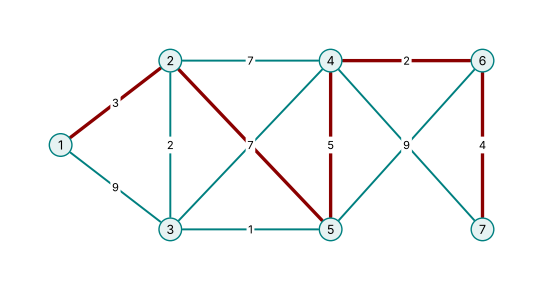

In [4]:
A7 = [(1, 2, 3), (1, 3, 9), (2, 3, 2), (2, 4, 7), (2, 5, 1), (3, 4, 7),
      (3, 5, 1), (4, 5, 5), (4, 6, 2), (4, 7, 8), (5, 6, 9), (6, 7, 4)]
p7 = {1: (0, 1), 2: (1.3, 2), 3: (1.3, 0), 4: (3.2, 2), 5: (3.2, 0), 6: (5, 2), 7: (5, 0)}
W7 = matriz_pesos(7, A7)
mostrar_pesos(W7)
D, previo = dijkstra(W7, 1, traza=True)
cam = camino(previo, 1, 7)
print("camino mínimo de 1 a 7:", cam, "peso", D[7])
dibujar(p7, A7, resaltar=list(zip(cam, cam[1:])), tam=(6, 3));

In [5]:
for j in range(2, 8):
    print(f"1 -> {j}: peso {fmt_peso(D[j]):>2}, camino {camino(previo, 1, j)}")

1 -> 2: peso  3, camino [1, 2]
1 -> 3: peso  5, camino [1, 2, 3]
1 -> 4: peso  9, camino [1, 2, 5, 4]
1 -> 5: peso  4, camino [1, 2, 5]
1 -> 6: peso 11, camino [1, 2, 5, 4, 6]
1 -> 7: peso 15, camino [1, 2, 5, 4, 6, 7]


## 2. El algoritmo de Warshall

$W^{(k)}$ tiene los pesos mínimos de los caminos cuyos vértices intermedios están en $\{x_1,\dots,x_k\}$:
$$w^{(k)}_{ij}=\min\{w^{(k-1)}_{ij},\ w^{(k-1)}_{ik}+w^{(k-1)}_{kj}\}.$$
La matriz `sig` guarda, para cada par, por qué vértice salir para seguir un camino mínimo.

In [6]:
def warshall(W, traza=False):
    """
    W^(k) contiene los pesos mínimos de los caminos cuyos vértices intermedios
    están en {1, ..., k}:
        w_ij^(k) = min( w_ij^(k-1), w_ik^(k-1) + w_kj^(k-1) ).
    Devuelve (W*, siguiente); siguiente[i][j] es el vértice que sigue a i en un
    camino mínimo de i a j. Con traza=True devuelve también la lista de las W^(k).
    """
    n = len(W)
    A = [fila[:] for fila in W]
    sig = [[(j if W[i][j] < INF else None) for j in range(n)] for i in range(n)]
    pasos = [[fila[:] for fila in A]]
    for k in range(n):
        for i in range(n):
            for j in range(n):
                if A[i][k] + A[k][j] < A[i][j]:
                    A[i][j] = A[i][k] + A[k][j]
                    sig[i][j] = sig[i][k]
        pasos.append([fila[:] for fila in A])
    return (A, sig, pasos) if traza else (A, sig)


def camino_warshall(sig, i, j):
    """Camino mínimo de i a j (numerados desde 1) con la matriz `siguiente`."""
    if sig[i - 1][j - 1] is None:
        return None
    c = [i]
    while c[-1] != j or len(c) == 1:
        c.append(sig[c[-1] - 1][j - 1] + 1)
    return c

In [7]:
A6 = [(1, 2, 7), (1, 4, 2), (1, 6, 2), (2, 3, 4), (2, 4, 4), (2, 5, 1), (2, 6, 1), (3, 6, 2)]
p6 = {6: (2, 1.8), 1: (0, 0.8), 2: (2, 0.8), 3: (3.8, 0.8), 4: (1, -0.3), 5: (2.8, -0.3)}
W6 = matriz_pesos(6, A6)
Ws, sig, pasos = warshall(W6, traza=True)
mostrar_varias(pasos[0:3], ["W(0)", "W(1)", "W(2)"])
print()
mostrar_varias(pasos[3:5], ["W(3)", "W(4)"])
print()
mostrar_varias(pasos[5:7], ["W(5)", "W(6) = W*"])

       W(0)                 W(1)                 W(2)       
  ∞  7  ∞  2  ∞  2     ∞  7  ∞  2  ∞  2    14  7 11  2  8  2
  7  ∞  4  4  1  1     7 14  4  4  1  1     7 14  4  4  1  1
  ∞  4  ∞  ∞  ∞  2     ∞  4  ∞  ∞  ∞  2    11  4  8  8  5  2
  2  4  ∞  ∞  ∞  ∞     2  4  ∞  4  ∞  4     2  4  8  4  5  4
  ∞  1  ∞  ∞  ∞  ∞     ∞  1  ∞  ∞  ∞  ∞     8  1  5  5  2  2
  2  1  2  ∞  ∞  ∞     2  1  2  4  ∞  4     2  1  2  4  2  2

       W(3)                 W(4)       
 14  7 11  2  8  2     4  6 10  2  7  2
  7  8  4  4  1  1     6  8  4  4  1  1
 11  4  8  8  5  2    10  4  8  8  5  2
  2  4  8  4  5  4     2  4  8  4  5  4
  8  1  5  5  2  2     7  1  5  5  2  2
  2  1  2  4  2  2     2  1  2  4  2  2

       W(5)              W(6) = W*     
  4  6 10  2  7  2     4  3  4  2  4  2
  6  2  4  4  1  1     3  2  3  4  1  1
 10  4  8  8  5  2     4  3  4  6  4  2
  2  4  8  4  5  4     2  4  6  4  5  4
  7  1  5  5  2  2     4  1  4  5  2  2
  2  1  2  4  2  2     2  1  2  4  2  2


camino mínimo de 1 a 5: [1, 6, 2, 5] peso 4


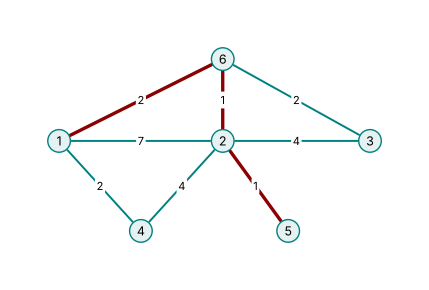

In [8]:
cam = camino_warshall(sig, 1, 5)
print("camino mínimo de 1 a 5:", cam, "peso", Ws[0][4])
dibujar(p6, A6, resaltar=list(zip(cam, cam[1:])), tam=(5, 3));

**La diagonal.** $w^*_{ii}$ es el peso de la trayectoria cerrada más corta desde $x_i$; en un grafo no dirigido es ir y volver por la arista más ligera. Con Dijkstra se obtiene empezando con $L=\emptyset$:

In [9]:
D, previo = dijkstra(W6, 1, ciclos=True, traza=True)
print("D(1) =", D[1], " trayectoria:", camino(previo, 1, 1))
print("diagonal de W*:", [Ws[i][i] for i in range(6)])

  L                       D(1)  D(2)  D(3)  D(4)  D(5)  D(6)
  ∅                          ∞     7     ∞     2     ∞     2
  {4}                        4     6     ∞     2     ∞     2
  {4, 6}                     4     3     4     2     ∞     2
  {4, 6, 2}                  4     3     4     2     4     2
  {4, 6, 2, 1}               4     3     4     2     4     2
  {4, 6, 2, 1, 3}            4     3     4     2     4     2
D(1) = 4  trayectoria: [1, 4, 1]
diagonal de W*: [4, 2, 4, 4, 2, 2]


## 3. Problema 4.17

Cinco ciudades $A,\dots,E$ (vértices $1,\dots,5$) con las distancias en cientos de km. La central debe estar en la ciudad con menor suma de distancias a las demás. Ponemos ceros en la diagonal: estar en la propia ciudad no cuesta nada.

In [10]:
ciudades = "ABCDE"
W = matriz_pesos(5, [(1, 2, 3), (1, 4, 5), (2, 3, 2), (2, 4, 6), (3, 5, 4), (5, 4, 1)])
for i in range(5):
    W[i][i] = 0
Ws, sig = warshall(W)
mostrar_pesos(Ws, list(ciudades))
sumas = {c: 100 * sum(f) for c, f in zip(ciudades, Ws)}
print(sumas, "-> central en", min(sumas, key=sumas.get))

     A  B  C  D  E
  A  0  3  5  5  6
  B  3  0  2  6  6
  C  5  2  0  5  4
  D  5  6  5  0  1
  E  6  6  4  1  0
{'A': 1900, 'B': 1700, 'C': 1600, 'D': 1700, 'E': 1700} -> central en C


## 4. Dígrafos

Los dos algoritmos sirven sin cambios para grafos dirigidos: basta construir la matriz con `dirigido=True`.

**Problema 4.23.** Dijkstra desde $x_3$ con $L=\emptyset$ (así $D(3)$ dice si hay un ciclo por $x_3$):

In [11]:
I = INF
W23 = [[I, 4, I, I, I, I, 2],
       [I, I, I, I, I, I, 2],
       [2, 8, I, 8, I, 1, I],
       [I, 1, I, I, I, I, I],
       [I, I, I, I, I, I, I],
       [3, I, I, 4, I, I, 7],
       [I, I, I, 3, I, I, I]]
D, previo = dijkstra(W23, 3, ciclos=True, traza=True)
for j in range(1, 8):
    print(f"x3 -> x{j}: {fmt_peso(D[j]):>2}  {camino(previo, 3, j)}")

  L                       D(1)  D(2)  D(3)  D(4)  D(5)  D(6)  D(7)
  ∅                          2     8     ∞     8     ∞     1     ∞
  {6}                        2     8     ∞     5     ∞     1     8
  {6, 1}                     2     6     ∞     5     ∞     1     4
  {6, 1, 7}                  2     6     ∞     5     ∞     1     4
  {6, 1, 7, 4}               2     6     ∞     5     ∞     1     4
  {6, 1, 7, 4, 2}            2     6     ∞     5     ∞     1     4
  {6, 1, 7, 4, 2, 3}         2     6     ∞     5     ∞     1     4
x3 -> x1:  2  [3, 1]
x3 -> x2:  6  [3, 1, 2]
x3 -> x3:  ∞  None
x3 -> x4:  5  [3, 6, 4]
x3 -> x5:  ∞  None
x3 -> x6:  1  [3, 6]
x3 -> x7:  4  [3, 1, 7]


No hay ciclo por $x_3$ ($D(3)=\infty$) ni camino de $x_3$ a $x_5$. A $x_2$ se llega con peso $6$ por dos caminos: $x_3x_1x_2$ y $x_3x_6x_4x_2$.

**Problema 4.26.** Pesos $w(v_i,v_j)=|i-j|$; Dijkstra desde $v_6$:

In [12]:
arcos = [(1, 2), (1, 3), (1, 4), (2, 3), (2, 5), (4, 3), (4, 5), (5, 1), (6, 2), (6, 3), (6, 4), (6, 5)]
W26 = matriz_pesos(6, [(i, j, abs(i - j)) for i, j in arcos], dirigido=True)
mostrar_pesos(W26)
D, previo = dijkstra(W26, 6, ciclos=True, traza=True)

     1  2  3  4  5  6
  1  ∞  1  2  3  ∞  ∞
  2  ∞  ∞  1  ∞  3  ∞
  3  ∞  ∞  ∞  ∞  ∞  ∞
  4  ∞  ∞  1  ∞  1  ∞
  5  4  ∞  ∞  ∞  ∞  ∞
  6  ∞  4  3  2  1  ∞
  L                       D(1)  D(2)  D(3)  D(4)  D(5)  D(6)
  ∅                          ∞     4     3     2     1     ∞
  {5}                        5     4     3     2     1     ∞
  {5, 4}                     5     4     3     2     1     ∞
  {5, 4, 3}                  5     4     3     2     1     ∞
  {5, 4, 3, 2}               5     4     3     2     1     ∞
  {5, 4, 3, 2, 1}            5     4     3     2     1     ∞


## 5. Comparación de tiempos

Dijkstra hace unas $n^2$ operaciones para un vértice de partida; Warshall, unas $n^3$ para todos. Si se quieren todos los pares, repetir Dijkstra desde cada vértice también cuesta del orden de $n^3$.

In [13]:
import random, time
random.seed(2026)
for n in (25, 50, 100, 200):
    aristas = [(i, j, random.randint(1, 20)) for i in range(1, n + 1) for j in range(i + 1, n + 1)
               if random.random() < 4 / n]
    W = matriz_pesos(n, aristas)
    t0 = time.perf_counter(); dijkstra(W, 1); t1 = time.perf_counter()
    todos = [dijkstra(W, p)[0] for p in range(1, n + 1)]; t2 = time.perf_counter()
    Ws, _ = warshall(W); t3 = time.perf_counter()
    assert all(todos[p - 1][j] == Ws[p - 1][j - 1] for p in range(1, n + 1) for j in range(1, n + 1) if j != p)
    print(f"n = {n:>3}: Dijkstra desde 1 {t1 - t0:.4f} s | desde todos {t2 - t1:6.2f} s | Warshall {t3 - t2:6.2f} s")

n =  25: Dijkstra desde 1 0.0001 s | desde todos   0.00 s | Warshall   0.00 s
n =  50: Dijkstra desde 1 0.0004 s | desde todos   0.02 s | Warshall   0.01 s


n = 100: Dijkstra desde 1 0.0016 s | desde todos   0.17 s | Warshall   0.08 s


n = 200: Dijkstra desde 1 0.0065 s | desde todos   1.24 s | Warshall   0.71 s


## Referencias

- Dijkstra, E. W. (1959). A note on two problems in connexion with graphs. *Numerische Mathematik*, 1, 269–271.
- Floyd, R. W. (1962). Algorithm 97: Shortest path. *Communications of the ACM*, 5(6), 345.
- Warshall, S. (1962). A theorem on Boolean matrices. *Journal of the ACM*, 9(1), 11–12.